# Chapter 6: Distributed (Cell-Free) Massive MIMO

Companion code for *Robust Adaptive Beamforming and Its Applications* by Ayman Elnashar (Wiley, forthcoming).

This notebook reproduces every simulation figure of Chapter 6 (Figures 6.1–6.10), Tables 6.2–6.6 and the numbers quoted in the text. The chapter brings worst-case robust combining to cell-free massive MIMO, where every access point (AP) holds its own imperfect estimate of each user's channel inside a bounded per-AP uncertainty ball. Two realizations share one multi-constraint robust LCMV solver:

* **CF-RAB (centralized)** stacks all APs and solves one joint robust problem at the central processing unit (CPU) with Algorithm 6.1;
* **D-CF-RAB** solves one small exact single-ball problem per AP (Section 6.3.6), combines the local outputs with an L-dimensional CPU Wiener combiner and runs a cross-AP rescaling check of the worst-case combined response (Algorithm 6.2).

They are compared with MR, LP-MMSE and P-MMSE combining [6], matched two-stage baselines that apply the same CPU combiner to a different local stage (MR, LP-MMSE and local MVDR), INCM reconstruction [20] and the centralized primary-ball SOCP benchmark.

## Configuration

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))   # chapter folder, so that `ch6cfrab` imports without installation
QUICK = False             # True: two to three realizations per point (smoke test)
REUSE_DATA = True         # True: reuse the simulation data in FIGDIR/data when it is complete (e.g. written by scripts/generate_figures.py)
FIGDIR = os.path.abspath('../figures')
os.environ.update(FIGDIR=FIGDIR, RAB_INLINE='1')
%matplotlib inline
from ch6cfrab import scenarios as S
from ch6cfrab.figures import *
DATA = os.path.join(FIGDIR, 'data')

def show(key):
    print(json.dumps(RESULTS[key], ensure_ascii=False, indent=1)[:3000])

## Library

`ch6cfrab.algorithms` holds the cell-free channel generator of Section 6.2 (Rician directions at 7.125 GHz, normalized per-AP gains or the path-loss model of Section 6.7.1, AR(1) channel evolution, CSI delay, errors on the boundary of the declared ball (6.2) or the other error laws of Section 6.7.13), the multi-constraint robust LCMV solver of Algorithm 6.1 (`rab_step`) with the constraint grid (6.11) (`build_constraint_grid`), the exact single-ball solution of Section 6.3.6 (`exact_wc`), the D-CF-RAB step of Algorithm 6.2 (`cf_distributed_step`: local solves, CPU Wiener combiner (6.13), cross-AP rescaling check (6.14)), CF-RAB (`beamformer_cf_rab`), the comparison combiners and the snapshot loop that scores every method on the same snapshots (`run_snapshot_trace`).

`ch6cfrab.scenarios` holds one stage per group of results; `ch6cfrab.figures` draws the figures and tables; `ch6cfrab.verify` compares every regenerated number with the value quoted in the chapter.

## Settings (Section 6.7.1)

Service area 500 m × 500 m; L = 16 APs with M = 8 antennas each (uniform linear arrays at half-wavelength spacing), K = 4 users, Rician factor 7 dB; per-antenna SNR 10 dB, INR 10 dB, ε = 0.10, zero CSI delay. Per-AP channel gains normalized to √M times a gain uniform within ±3 dB. Every CSI error lies on the boundary of the declared relative ball (6.2); true channels follow AR(1) with correlation 0.995 per snapshot. Covariance-based methods use the population covariance (6.4) at the first snapshot of each trace. D-CF-RAB updates at every snapshot with the local bound level c = 0.98; the other combiners are rebuilt every fifth snapshot after the first quarter of the trace, and all methods are scored on those nine rebuild snapshots of each 60-snapshot trace. Figures 6.1–6.7 average five realizations per point with pointwise 95% Student-t intervals; paired differences use 20 realizations.

## Experiments

Each stage runs in its own process and writes its data and printed output into `FIGDIR/data`. The full counts take about 40 minutes on two cores; the timing stage of Figure 6.6 runs alone at the end.

In [2]:
def complete():
    return all(os.path.exists(os.path.join(DATA, s + '.json')) for s in S.ALL_STAGES)

if REUSE_DATA and complete() and not QUICK:
    print('reusing the simulation data in', DATA)
else:
    S.run_groups(DATA, groups=S.ALL_STAGES, jobs=2, quick=QUICK)
for s in S.ALL_STAGES:
    print(f"{s:8s} {json.load(open(os.path.join(DATA, s + '.json')))['seconds']:8.1f} s")

reusing the simulation data in /home/claude/robust-adaptive-beamforming-book/chapter-06/figures/data
B1         1389.6 s
lbound      640.3 s
A1          200.0 s
A2          312.6 s
fig2        149.4 s
paired      252.8 s
B2          534.8 s
audits       39.6 s
train        29.5 s
fig1         25.0 s
fig3         87.9 s
fig4         75.2 s
fig7         19.0 s
fig8         31.2 s
fig9          4.9 s
fig5         29.4 s
A4          260.1 s
fig10         1.0 s
A3           14.9 s
A5            3.2 s
fig6         10.5 s


## Figure 6.1: SINR against the number of APs

L ∈ {4, 8, 16}, ε = 0.10, SNR = 10 dB; five realizations per point (seeds 100 + 37t).

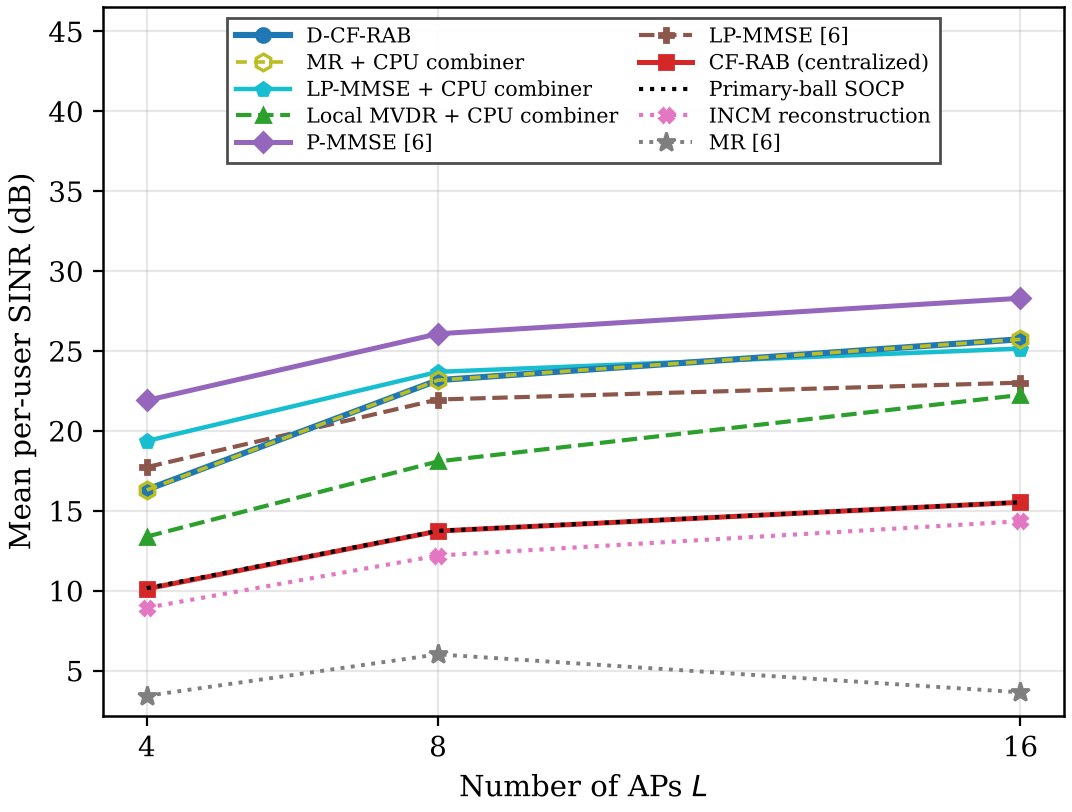

{
 "x": "number of APs L",
 "points": {
  "4": {
   "D-CF-RAB": [
    16.323,
    2.901,
    13.04
   ],
   "MR + CPU combiner": [
    16.301,
    2.922,
    13.002
   ],
   "LP-MMSE + CPU combiner": [
    19.367,
    1.279,
    17.362
   ],
   "Local MVDR + CPU combiner": [
    13.386,
    0.739,
    11.937
   ],
   "CF-RAB (centralized)": [
    10.115,
    1.195,
    8.521
   ],
   "Primary-ball SOCP": [
    10.158,
    1.178,
    8.559
   ],
   "P-MMSE [6]": [
    21.907,
    1.31,
    20.226
   ],
   "LP-MMSE [6]": [
    17.733,
    1.384,
    15.842
   ],
   "INCM reconstruction": [
    8.934,
    1.562,
    6.163
   ],
   "MR [6]": [
    3.425,
    2.963,
    0.828
   ]
  },
  "8": {
   "D-CF-RAB": [
    23.176,
    1.588,
    21.949
   ],
   "MR + CPU combiner": [
    23.173,
    1.603,
    21.946
   ],
   "LP-MMSE + CPU combiner": [
    23.694,
    1.41,
    22.492
   ],
   "Local MVDR + CPU combiner": [
    18.09,
    0.571,
    16.71
   ],
   "CF-RAB (centralized)": [
    13.

In [3]:
fig_6_1()
show('Figure 6.1')

## Figure 6.2: robustness to the CSI uncertainty radius

Mean (left) and worst-user (right) SINR at L = 16 for ε from 0.005 to 0.50 (seeds 700 + 37t).

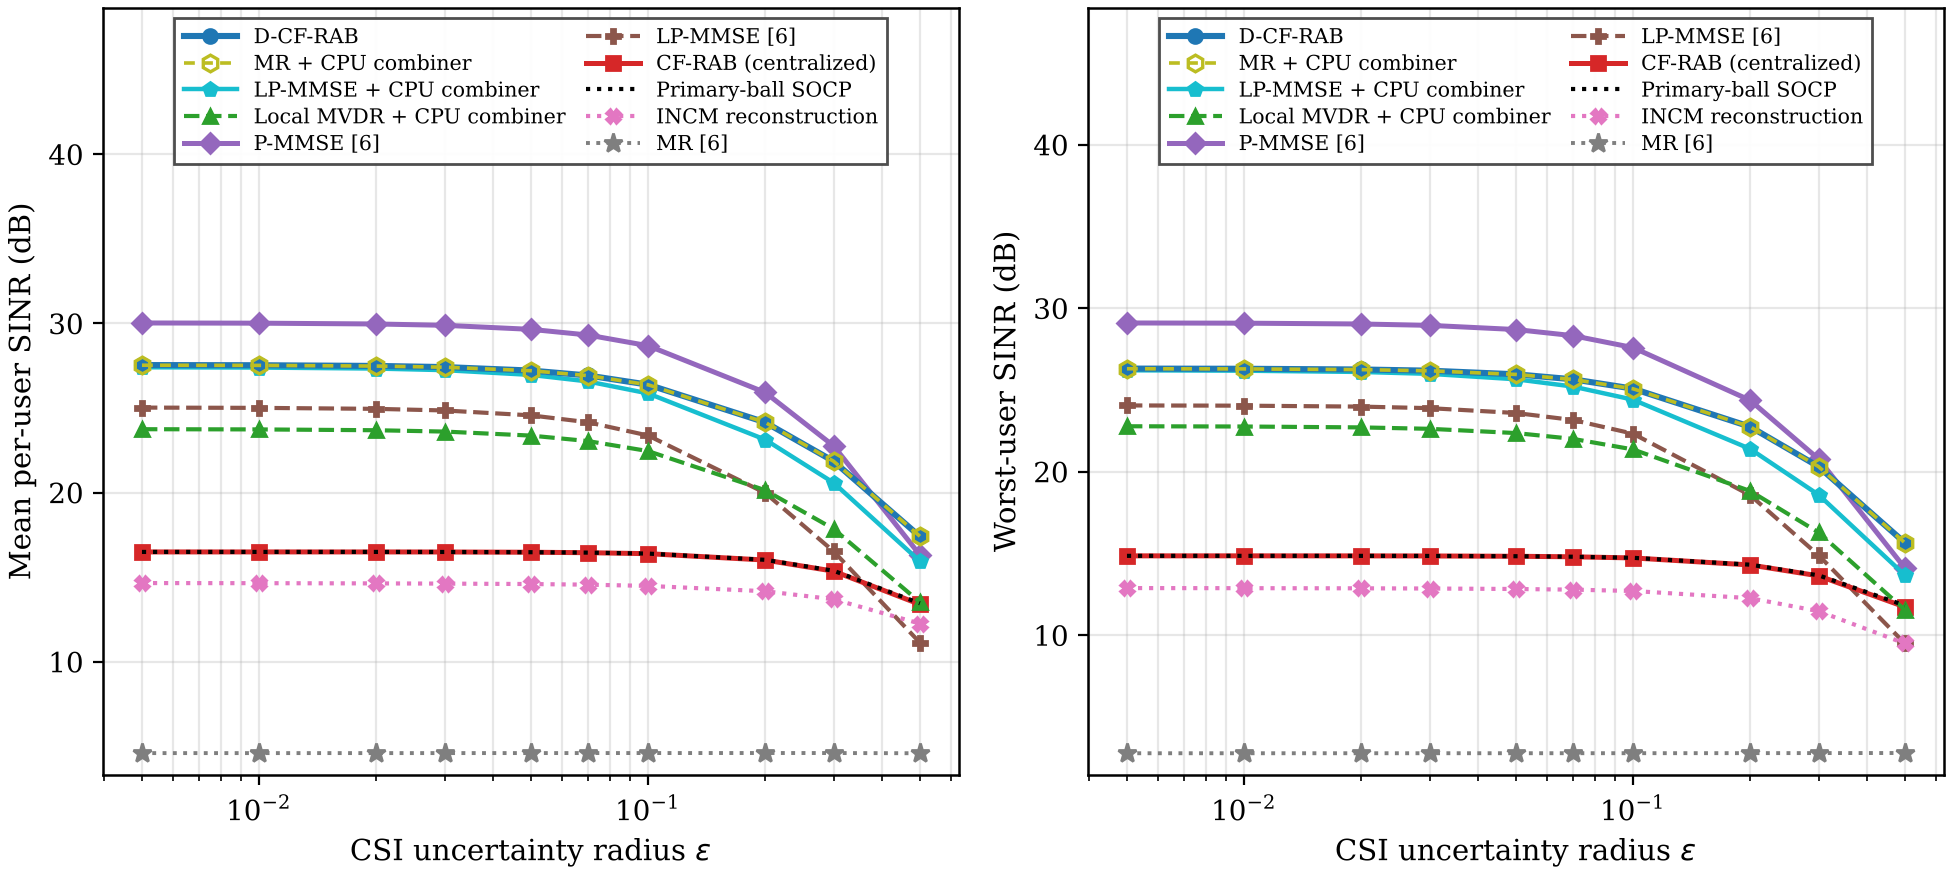

{
 "x": "CSI uncertainty radius eps",
 "points": {
  "0.005": {
   "D-CF-RAB": [
    27.537,
    1.659,
    26.307
   ],
   "MR + CPU combiner": [
    27.528,
    1.663,
    26.298
   ],
   "LP-MMSE + CPU combiner": [
    27.405,
    1.455,
    26.202
   ],
   "Local MVDR + CPU combiner": [
    23.745,
    0.958,
    22.778
   ],
   "CF-RAB (centralized)": [
    16.489,
    0.757,
    14.851
   ],
   "Primary-ball SOCP": [
    16.49,
    0.757,
    14.852
   ],
   "P-MMSE [6]": [
    30.026,
    0.922,
    29.097
   ],
   "LP-MMSE [6]": [
    25.023,
    1.767,
    24.052
   ],
   "INCM reconstruction": [
    14.65,
    1.868,
    12.88
   ],
   "MR [6]": [
    4.597,
    4.523,
    2.777
   ]
  },
  "0.01": {
   "D-CF-RAB": [
    27.527,
    1.66,
    26.296
   ],
   "MR + CPU combiner": [
    27.519,
    1.664,
    26.287
   ],
   "LP-MMSE + CPU combiner": [
    27.39,
    1.459,
    26.178
   ],
   "Local MVDR + CPU combiner": [
    23.733,
    0.957,
    22.764
   ],
   "CF-RAB (ce

In [4]:
fig_6_2()
show('Figure 6.2')

## Figure 6.3: SINR against the per-antenna SNR

L = 16, ε = 0.10, SNR from −5 to 20 dB (seeds 600 + 37t).

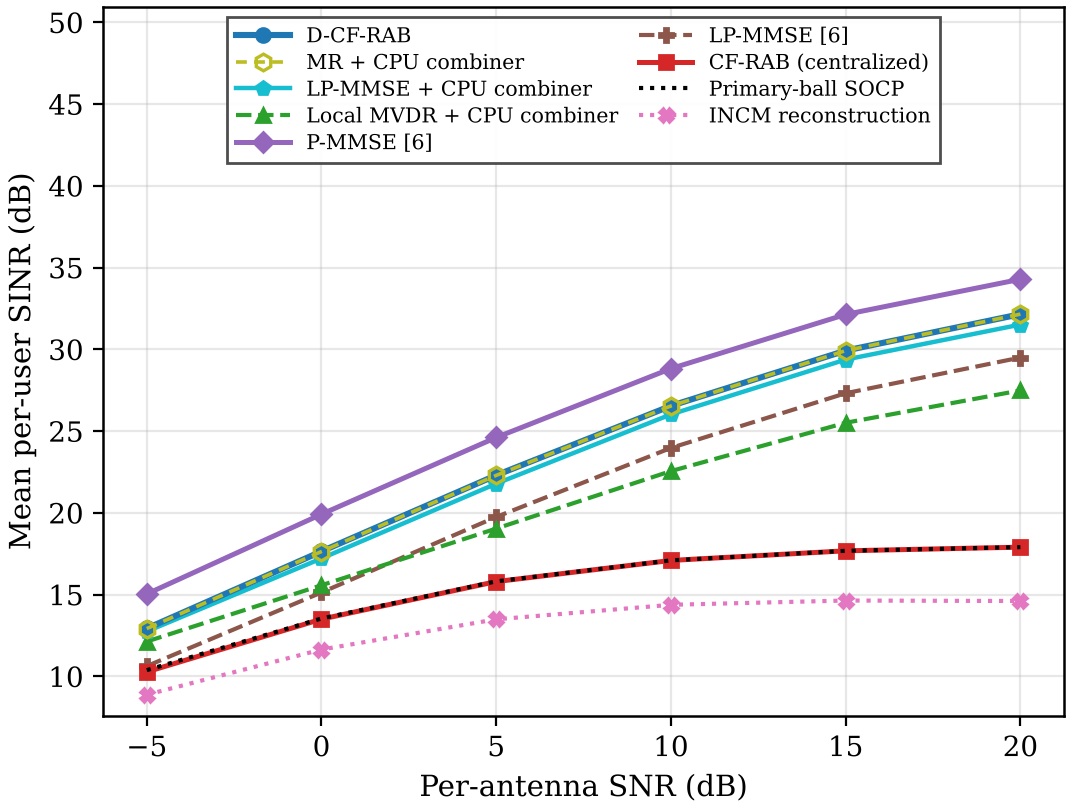

{
 "x": "per-antenna SNR (dB)",
 "points": {
  "-5": {
   "D-CF-RAB": [
    12.928,
    0.595,
    11.982
   ],
   "MR + CPU combiner": [
    12.92,
    0.599,
    11.971
   ],
   "LP-MMSE + CPU combiner": [
    12.746,
    0.806,
    11.807
   ],
   "Local MVDR + CPU combiner": [
    12.129,
    0.303,
    11.36
   ],
   "CF-RAB (centralized)": [
    10.273,
    0.689,
    9.392
   ],
   "Primary-ball SOCP": [
    10.379,
    0.671,
    9.511
   ],
   "P-MMSE [6]": [
    15.037,
    0.264,
    14.363
   ],
   "LP-MMSE [6]": [
    10.626,
    1.323,
    9.715
   ],
   "INCM reconstruction": [
    8.876,
    0.563,
    7.883
   ]
  },
  "0": {
   "D-CF-RAB": [
    17.644,
    0.598,
    16.644
   ],
   "MR + CPU combiner": [
    17.636,
    0.602,
    16.628
   ],
   "LP-MMSE + CPU combiner": [
    17.213,
    0.833,
    16.209
   ],
   "Local MVDR + CPU combiner": [
    15.571,
    0.397,
    14.823
   ],
   "CF-RAB (centralized)": [
    13.501,
    1.022,
    12.298
   ],
   "Primary-

In [5]:
fig_6_3()
show('Figure 6.3')

## Figure 6.4: CSI delay

L = 16, delay τ ∈ {0, 1, 4, 16, 64} snapshots (seeds 200 + 37t).

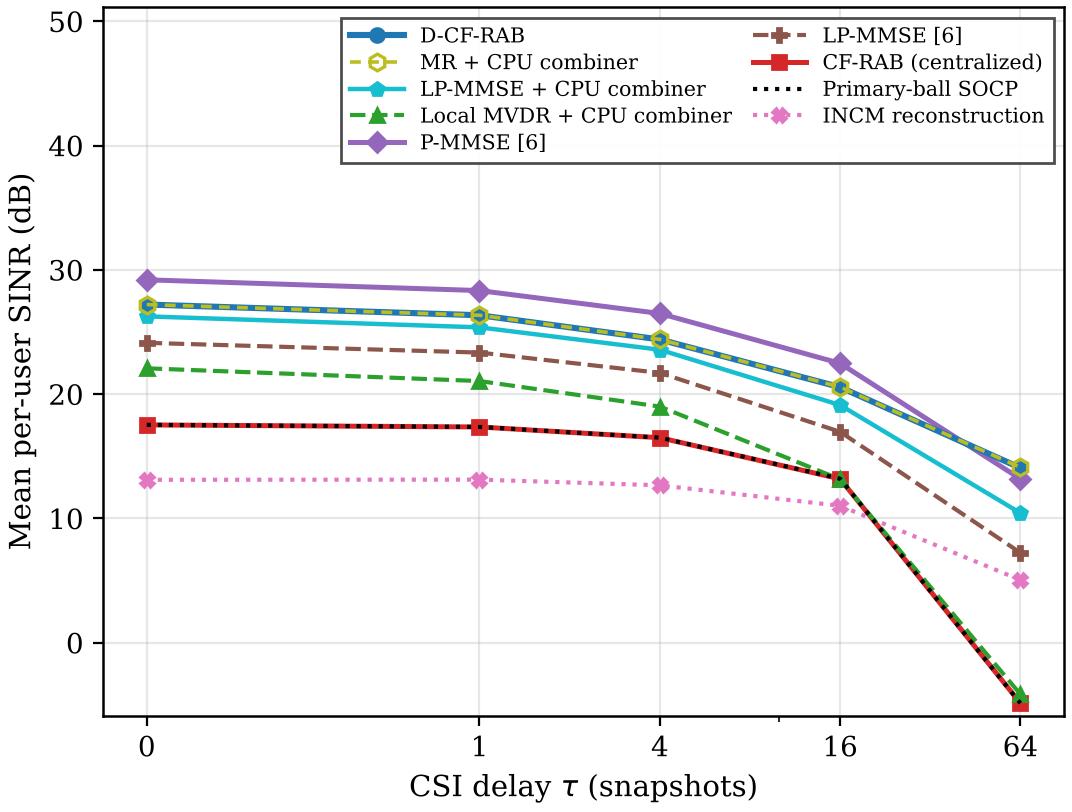

{
 "x": "CSI delay tau (snapshots)",
 "points": {
  "0": {
   "D-CF-RAB": [
    27.212,
    0.996,
    25.639
   ],
   "MR + CPU combiner": [
    27.209,
    1.0,
    25.634
   ],
   "LP-MMSE + CPU combiner": [
    26.259,
    1.218,
    24.701
   ],
   "Local MVDR + CPU combiner": [
    22.08,
    0.6,
    21.211
   ],
   "CF-RAB (centralized)": [
    17.526,
    1.611,
    16.182
   ],
   "Primary-ball SOCP": [
    17.531,
    1.61,
    16.187
   ],
   "P-MMSE [6]": [
    29.202,
    0.696,
    28.095
   ],
   "LP-MMSE [6]": [
    24.131,
    1.195,
    22.625
   ],
   "INCM reconstruction": [
    13.11,
    2.131,
    8.699
   ]
  },
  "1": {
   "D-CF-RAB": [
    26.352,
    1.039,
    24.798
   ],
   "MR + CPU combiner": [
    26.35,
    1.043,
    24.793
   ],
   "LP-MMSE + CPU combiner": [
    25.376,
    1.283,
    23.728
   ],
   "Local MVDR + CPU combiner": [
    21.055,
    0.745,
    20.49
   ],
   "CF-RAB (centralized)": [
    17.36,
    1.549,
    15.914
   ],
   "Primary-

In [6]:
fig_6_4()
show('Figure 6.4')

## Figure 6.5: heterogeneous per-AP CSI quality

Uniform ε = 0.10 and tiered per-AP radii, L = 16 (seeds 300 + 37t); the circles mark the primary-ball SOCP.

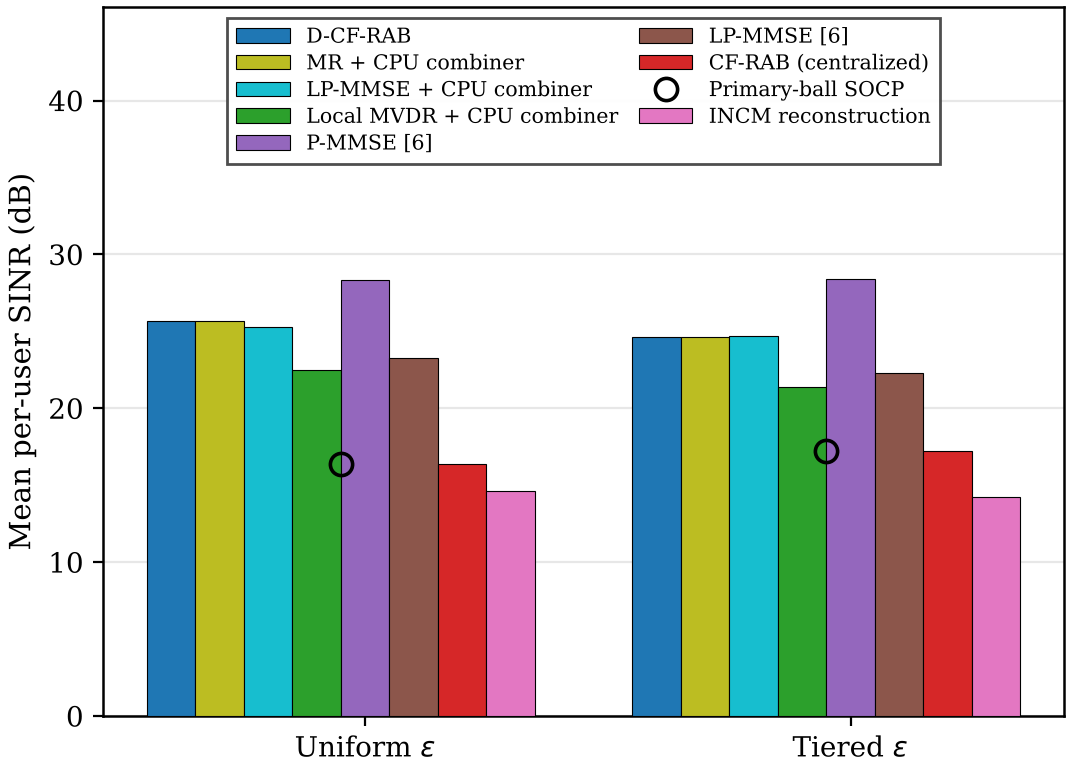

{
 "x": "per-AP CSI uncertainty profile",
 "points": {
  "uniform": {
   "D-CF-RAB": [
    25.654,
    1.013,
    24.021
   ],
   "MR + CPU combiner": [
    25.646,
    1.013,
    24.008
   ],
   "LP-MMSE + CPU combiner": [
    25.309,
    1.1,
    23.887
   ],
   "Local MVDR + CPU combiner": [
    22.458,
    0.575,
    21.702
   ],
   "CF-RAB (centralized)": [
    16.385,
    1.12,
    14.589
   ],
   "Primary-ball SOCP": [
    16.391,
    1.12,
    14.597
   ],
   "P-MMSE [6]": [
    28.35,
    0.587,
    27.338
   ],
   "LP-MMSE [6]": [
    23.27,
    0.756,
    21.72
   ],
   "INCM reconstruction": [
    14.594,
    0.985,
    12.771
   ]
  },
  "tiered": {
   "D-CF-RAB": [
    24.613,
    0.83,
    22.655
   ],
   "MR + CPU combiner": [
    24.604,
    0.821,
    22.63
   ],
   "LP-MMSE + CPU combiner": [
    24.672,
    1.308,
    23.327
   ],
   "Local MVDR + CPU combiner": [
    21.366,
    1.767,
    20.416
   ],
   "CF-RAB (centralized)": [
    17.193,
    0.937,
    16.232


In [7]:
fig_6_5()
show('Figure 6.5')

## Figure 6.6: wall-clock and fronthaul cost

Single-thread time per weight update measured on this machine (30-snapshot traces, five realizations), and the listed CSI and control bytes per user update of Sections 6.4.2 and 6.5.4. Times depend on the machine.

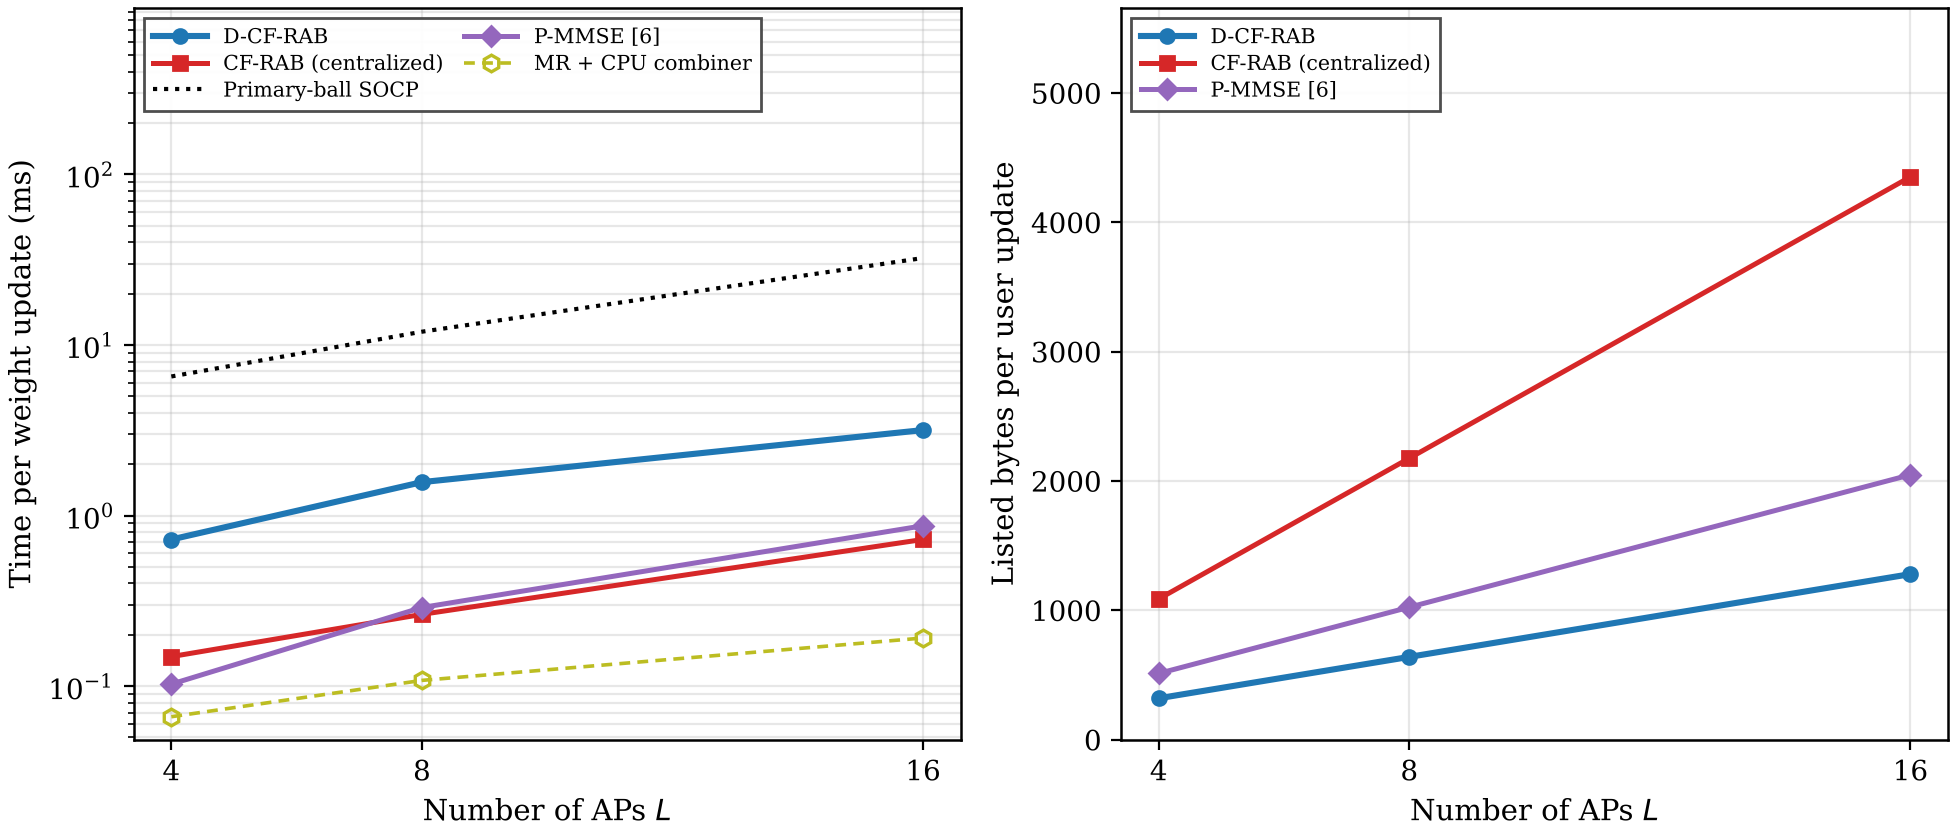

{
 "time per weight update (ms, this machine)": {
  "4": {
   "D-CF-RAB": 0.7237,
   "CF-RAB (centralized)": 0.149,
   "Primary-ball SOCP": 6.5365,
   "P-MMSE [6]": 0.1027,
   "MR + CPU combiner": 0.0662
  },
  "8": {
   "D-CF-RAB": 1.57,
   "CF-RAB (centralized)": 0.2635,
   "Primary-ball SOCP": 11.9608,
   "P-MMSE [6]": 0.289,
   "MR + CPU combiner": 0.1081
  },
  "16": {
   "D-CF-RAB": 3.1706,
   "CF-RAB (centralized)": 0.7244,
   "Primary-ball SOCP": 32.3512,
   "P-MMSE [6]": 0.8713,
   "MR + CPU combiner": 0.1915
  }
 },
 "weight updates timed": {
  "4": {
   "D-CF-RAB": 600,
   "CF-RAB (centralized)": 100,
   "Primary-ball SOCP": 100,
   "P-MMSE [6]": 100,
   "MR + CPU combiner": 100
  },
  "8": {
   "D-CF-RAB": 600,
   "CF-RAB (centralized)": 100,
   "Primary-ball SOCP": 100,
   "P-MMSE [6]": 100,
   "MR + CPU combiner": 100
  },
  "16": {
   "D-CF-RAB": 600,
   "CF-RAB (centralized)": 100,
   "Primary-ball SOCP": 100,
   "P-MMSE [6]": 100,
   "MR + CPU combiner": 100
  }
 },
 "

In [8]:
fig_6_6()
show('Figure 6.6')

## Figure 6.7: sensitivity to the trace length

L = 8, SNR = 0 dB, traces of 5 to 80 snapshots (seeds 500 + 37t).

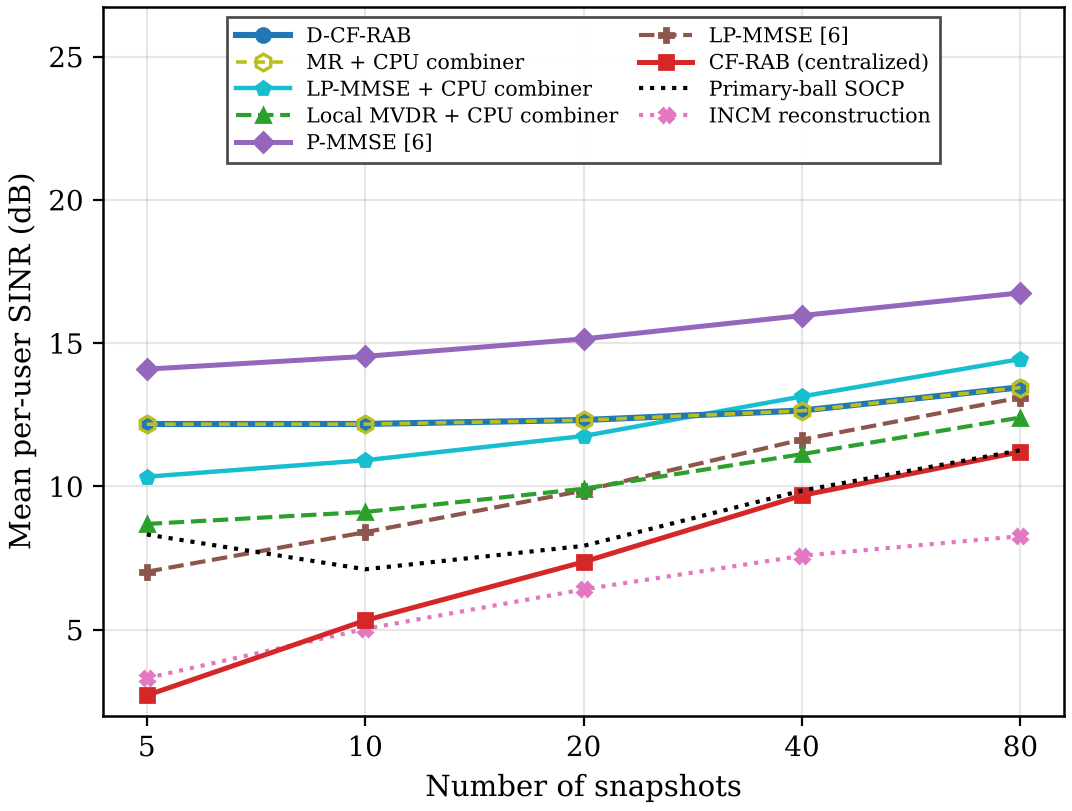

{
 "x": "trace length (snapshots)",
 "points": {
  "5": {
   "D-CF-RAB": [
    12.175,
    2.004,
    10.312
   ],
   "MR + CPU combiner": [
    12.168,
    2.0,
    10.316
   ],
   "LP-MMSE + CPU combiner": [
    10.336,
    5.257,
    7.518
   ],
   "Local MVDR + CPU combiner": [
    8.686,
    4.708,
    6.037
   ],
   "CF-RAB (centralized)": [
    2.703,
    0.339,
    2.383
   ],
   "Primary-ball SOCP": [
    8.319,
    1.204,
    7.291
   ],
   "P-MMSE [6]": [
    14.09,
    2.793,
    12.351
   ],
   "LP-MMSE [6]": [
    7.018,
    5.537,
    3.869
   ],
   "INCM reconstruction": [
    3.306,
    4.185,
    -0.17
   ]
  },
  "10": {
   "D-CF-RAB": [
    12.177,
    2.156,
    10.382
   ],
   "MR + CPU combiner": [
    12.17,
    2.152,
    10.385
   ],
   "LP-MMSE + CPU combiner": [
    10.909,
    4.37,
    8.502
   ],
   "Local MVDR + CPU combiner": [
    9.105,
    3.085,
    7.268
   ],
   "CF-RAB (centralized)": [
    5.317,
    0.293,
    4.933
   ],
   "Primary-ball SOCP"

In [9]:
fig_6_7()
show('Figure 6.7')

## Figure 6.8: comparison with the primary-ball conic benchmark

Left: objective excess of Algorithm 6.1 (CF-RAB) over the primary-ball SOCP on every CF-RAB solve of three realizations (seeds 700, 737, 774). Right: |SINR difference| between CF-RAB and the SOCP over the realizations of Figure 6.2.

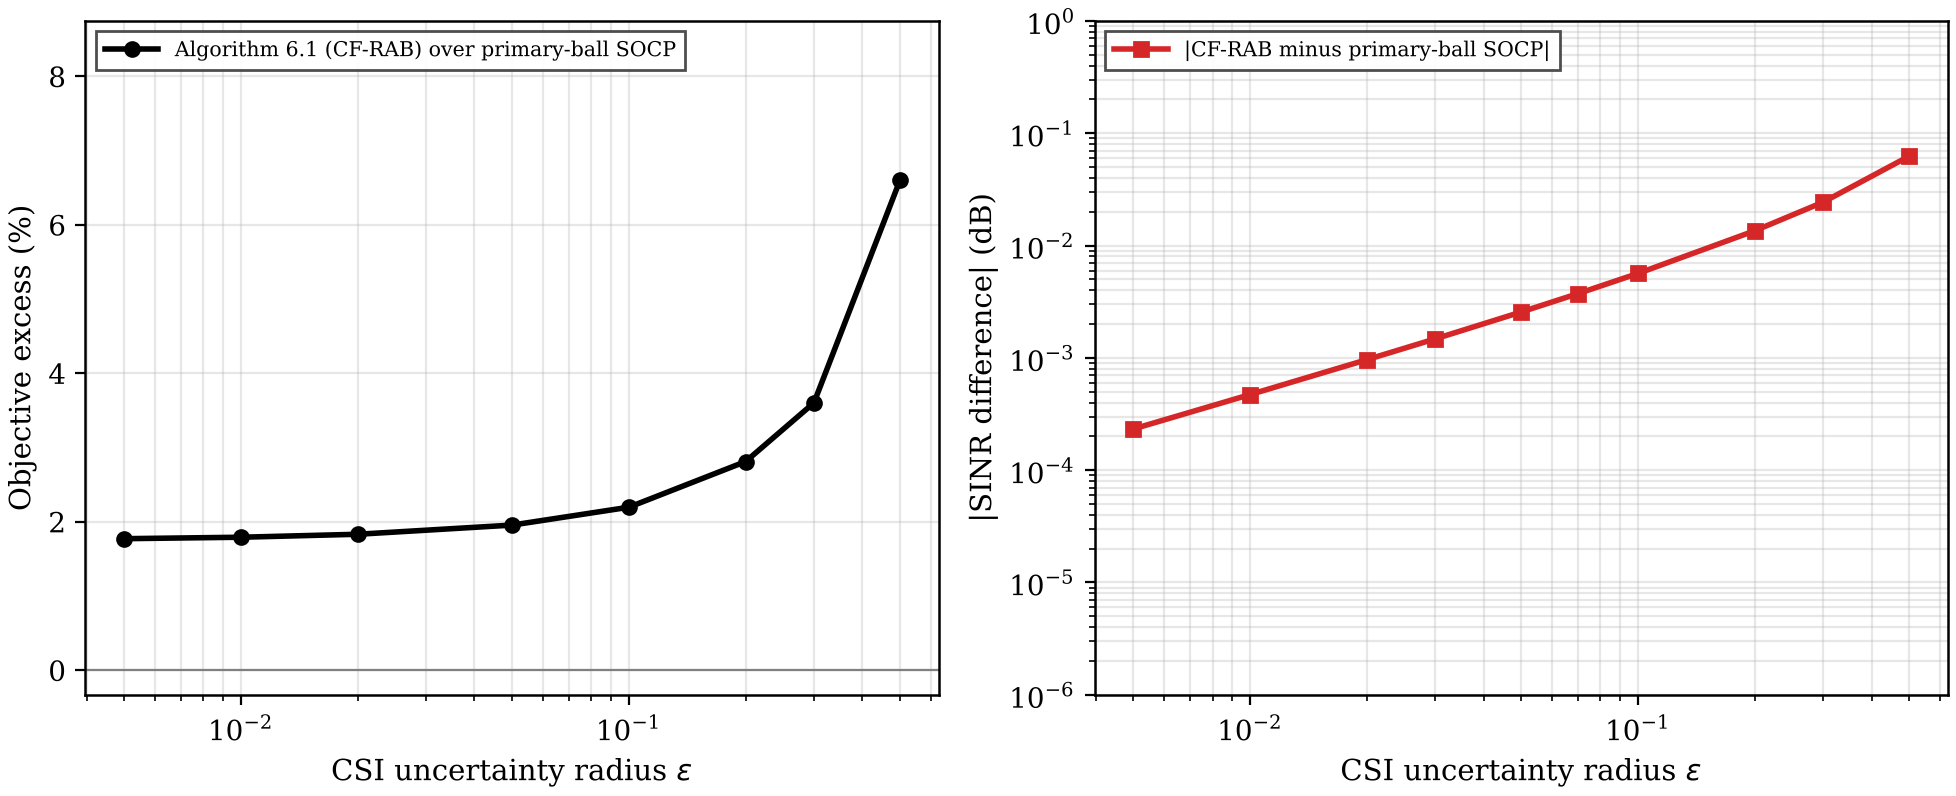

{
 "objective excess (%)": {
  "0.005": 1.772,
  "0.01": 1.792,
  "0.02": 1.832,
  "0.05": 1.955,
  "0.1": 2.196,
  "0.2": 2.811,
  "0.3": 3.602,
  "0.5": 6.6
 },
 "|CF-RAB minus primary-ball SOCP| (dB)": {
  "0.005": 0.00023,
  "0.01": 0.00047,
  "0.02": 0.00096,
  "0.03": 0.00148,
  "0.05": 0.00256,
  "0.07": 0.00373,
  "0.1": 0.00565,
  "0.2": 0.01357,
  "0.3": 0.02438,
  "0.5": 0.06258
 }
}


In [10]:
fig_6_8()
show('Figure 6.8')

## Figure 6.9: desired-signal contamination

Interference-plus-noise covariance of the first CF-RAB solve at seed 700, plus the desired signal on the true channel at 0 to 30 dB; the presumed channel is in error by ε; eight trials per point.

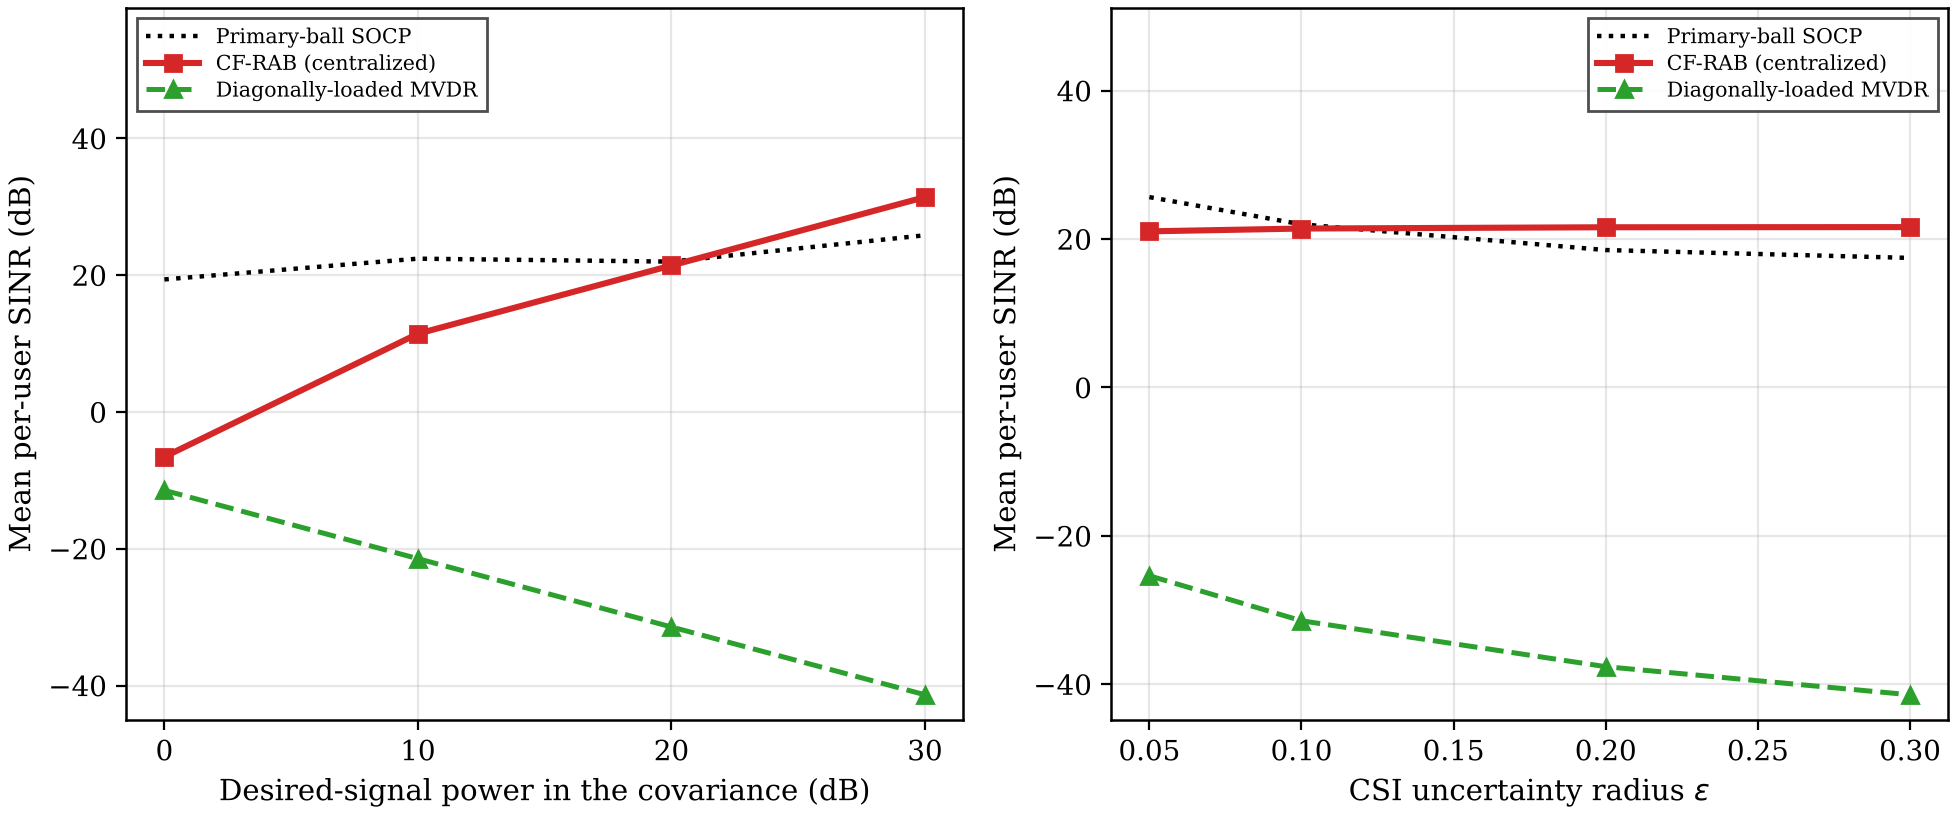

{
 "rows": [
  {
   "eps": 0.05,
   "soi_dB": 0,
   "MVDR": -5.396,
   "CF-RAB": -5.396,
   "centralized_sdp": 20.716
  },
  {
   "eps": 0.05,
   "soi_dB": 10,
   "MVDR": -15.387,
   "CF-RAB": 4.386,
   "centralized_sdp": 24.82
  },
  {
   "eps": 0.05,
   "soi_dB": 20,
   "MVDR": -25.377,
   "CF-RAB": 21.044,
   "centralized_sdp": 25.657
  },
  {
   "eps": 0.05,
   "soi_dB": 30,
   "MVDR": -35.291,
   "CF-RAB": 31.035,
   "centralized_sdp": 27.819
  },
  {
   "eps": 0.1,
   "soi_dB": 0,
   "MVDR": -11.459,
   "CF-RAB": -6.557,
   "centralized_sdp": 19.384
  },
  {
   "eps": 0.1,
   "soi_dB": 10,
   "MVDR": -21.45,
   "CF-RAB": 11.443,
   "centralized_sdp": 22.419
  },
  {
   "eps": 0.1,
   "soi_dB": 20,
   "MVDR": -31.441,
   "CF-RAB": 21.422,
   "centralized_sdp": 21.987
  },
  {
   "eps": 0.1,
   "soi_dB": 30,
   "MVDR": -41.354,
   "CF-RAB": 31.42,
   "centralized_sdp": 25.839
  },
  {
   "eps": 0.2,
   "soi_dB": 0,
   "MVDR": -17.646,
   "CF-RAB": 1.598,
   "centralized_sdp": 18.71

In [11]:
fig_6_9()
show('Figure 6.9')

## Figure 6.10: feasibility of rescaling the nominal direction

Direction change of Algorithm 6.1 from the loaded MVDR weight against the bound level c, for the joint problem (LM = 128) and the per-AP problems (M = 8); dotted lines: average primary-direction rescaling thresholds.

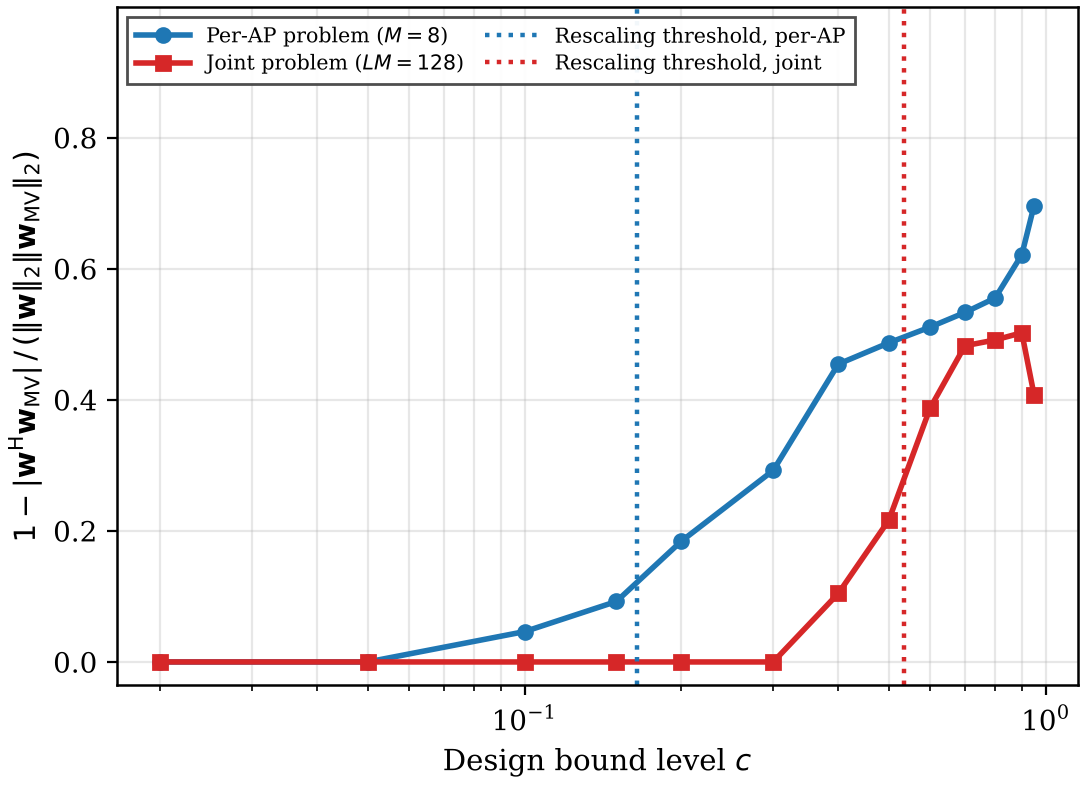

{
 "rescaling threshold, joint (LM = 128)": 0.5353,
 "rescaling threshold, per-AP (M = 8)": 0.164,
 "bound levels": [
  0.02,
  0.05,
  0.1,
  0.15,
  0.2,
  0.3,
  0.4,
  0.5,
  0.6,
  0.7,
  0.8,
  0.9,
  0.95
 ],
 "departure, per-AP": [
  0.0,
  0.0,
  0.04629,
  0.09226,
  0.1844,
  0.29221,
  0.45447,
  0.48692,
  0.51093,
  0.53324,
  0.55534,
  0.62134,
  0.69622
 ],
 "departure, joint": [
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.10459,
  0.21635,
  0.38717,
  0.48243,
  0.49131,
  0.50226,
  0.40747
 ]
}


In [12]:
fig_6_10()
show('Figure 6.10')

## Tables 6.2–6.6

Table 6.2: load-dependent bound selection with the exact covariance (bound, MVDR loading and the error scales of LP-MMSE and P-MMSE selected on eight training realizations, 20 held-out realizations). Table 6.3: the same with the 256-snapshot sample covariance. Table 6.4: CSI-error laws. Table 6.5: interferers without channel estimates (16-QAM users, impulsive interferers, sample covariance). Table 6.6: observations in the simulated parameter ranges.

In [13]:
tables()
for name in ('Table6_2_load_dependent_bound', 'Table6_3_sample_covariance', 'Table6_4_error_laws', 'Table6_5_external_interferers',
             'Table6_6_observations'):
    print(open(os.path.join(FIGDIR, name + '.md')).read())

| L | K | eps | c | D-CF-RAB | D-CF-RAB, c = 0.98 | MR + CPU | MVDR + CPU, selected | LP-MMSE + CPU | P-MMSE | Gain over c = 0.98 |
|---|---|---|---|---|---|---|---|---|---|---|
| 4 | 16 | 0.10 | 0.4 | 3.51 | 0.78 | 0.71 | 3.64 | 6.46 | 15.55 | 2.74 |
| 4 | 16 | 0.50 | 0.6 | 0.71 | −0.63 | −0.70 | 0.80 | 1.01 | 3.38 | 1.34 |
| 4 | 4 | 0.10 | 0.6 | 15.79 | 15.00 | 14.98 | 15.65 | 19.50 | 21.81 | 0.79 |
| 16 | 4 | 0.10 | 0.8 | 26.70 | 26.66 | 26.66 | 26.67 | 26.65 | 28.90 | 0.04 |
| 16 | 4 | 0.50 | 0.999 | 17.46 | 17.45 | 17.46 | 17.47 | 17.54 | 16.72 | 0.01 |
| 16 | 4 | 0.50 | 0.98 | 20.41 | 20.41 | 20.48 | 20.96 | 20.92 | 20.29 | 0.00 |

| L | K | eps | c | D-CF-RAB | MVDR + CPU, selected | MVDR + CPU, 1e-6 | D-CF-RAB minus MVDR + CPU, selected (95% interval) |
|---|---|---|---|---|---|---|---|
| 4 | 16 | 0.10 | 0.4 | 3.50 | 3.62 | 1.57 | −0.120 (−0.236, −0.004) |
| 4 | 16 | 0.50 | 0.6 | 0.70 | 0.79 | −2.33 | −0.083 (−0.129, −0.037) |
| 4 | 4 | 0.10 | 0.6 | 15.78 | 15.64 | 13.09 | 0.13

## Numbers quoted in the text

Bound selection of the main study (Section 6.7.1), the scalar-root solver check (Section 6.3.6), the 20-realization paired comparisons (Sections 6.7.2–6.7.3), the exact and Algorithm 6.1 local stages and the conic audits (Section 6.7.9), cross-AP rescaling outcomes (Section 6.7.11), load-dependent selection (Section 6.7.12), error laws and continuous-ball checks (Section 6.7.13) and the equal-mean tiers (Section 6.7.6).

In [14]:
text_numbers()
for k, v in RESULTS['Text'].items():
    print(k, json.dumps(v, ensure_ascii=False)[:1200])

bound level selected on training realizations (Section 6.7.1) 0.98
training SINR per bound level (dB) {"0.3": 18.564, "0.5": 20.523, "0.7": 21.386, "0.8": 21.624, "0.9": 21.747, "0.95": 21.766, "0.98": 21.767}
scalar-root solver check (Section 6.3.6) {"problems": 36, "max relative objective difference": 9.131009334028527e-10, "max constraint residual": 1.4210854715202004e-14, "speed-up over a loading-grid search, n = 8": 18.6}
paired comparisons, 20 realizations (D-CF-RAB minus method, dB, 95% interval) {"norm_L16_e010": {"MR+W": [0.008, 0.003, 0.013], "LP-MMSE+W": [0.605, 0.321, 0.89], "LMVDR+W": [3.51, 2.965, 4.055], "LP-MMSE": [2.783, 2.415, 3.15], "P-MMSE": [-2.55, -2.772, -2.328]}, "norm_L16_e050": {"MR+W": [-0.021, -0.033, -0.008], "LP-MMSE+W": [1.528, 1.229, 1.827], "LMVDR+W": [3.179, 2.497, 3.86], "LP-MMSE": [5.543, 5.141, 5.945], "P-MMSE": [0.871, 0.541, 1.201]}, "norm_L8_e010": {"MR+W": [0.009, 0.002, 0.015], "LP-MMSE+W": [-0.397, -0.794, -0.0], "LMVDR+W": [3.901, 3.282, 4.52

## Verification against the chapter

Every number quoted in the chapter is recomputed from the data and compared with the printed value (tolerance: half a unit of the last printed digit). Timings of Figure 6.6 are machine-dependent and are not compared.

In [15]:
from ch6cfrab import verify
n_diff = verify.main([FIGDIR])

Exact local solver: feasibility and tightness of every per-AP solve


  [OK ] bound level c = 0.98 is below 1
  [OK ] every local solve is feasible and tight  (3840 solves, margin range [-2.8e-14, 2.1e-14])

Error model: coverage of the declared ball of eq. (6.2)
  [OK ] every generated error satisfies eq. (6.2)  (4000/4000)
  [OK ] per-update timing recorded for every timed method  ({'D-CF-RAB': 600, 'CF-RAB': 100, 'centralized_sdp': 100, 'P-MMSE': 100, 'MR+W': 100})

Internal consistency
  [OK ] delay response is monotone
  [OK ] Fig. 6.4 at zero delay agrees with Fig. 6.3 at 10 dB  (27.21 vs 26.54)
  [OK ] bound level lies in (eps*_per-AP, 1)  (eps*_per-AP = 0.164)

Numbers quoted in the chapter: figures
  [OK ] Fig. 6.1: D-CF-RAB at L = 4  (16.323 vs 16.32 in the chapter)
  [OK ] Fig. 6.1: D-CF-RAB at L = 16  (25.736 vs 25.74 in the chapter)
  [OK ] Fig. 6.1: largest |MR + CPU minus D-CF-RAB|  (0.021586 vs 0.022 in the chapter)
  [OK ] Fig. 6.1: LP-MMSE + CPU minus D-CF-RAB at L = 4  (3.0445 vs 3.04 in the chapter)
  [OK ] Fig. 6.1: LP-MMSE + CPU min

In [16]:
print('results summary:', write_summary())

results summary: /home/claude/robust-adaptive-beamforming-book/chapter-06/figures/results_summary.json
